## Machine Learning CA1

In [1]:
# Load libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [2]:
# Load dataset
df = pd.read_csv("gallstone.csv")

In [3]:
# Check and display first 5 rows
df.head()

,Gallstone Status,Age,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Height,Weight,...,High Density Lipoprotein (HDL),Triglyceride,Aspartat Aminotransferaz (AST),Alanin Aminotransferaz (ALT),Alkaline Phosphatase (ALP),Creatinine,Glomerular Filtration Rate (GFR),C-Reactive Protein (CRP),Hemoglobin (HGB),Vitamin D
0,0,50,0,0,0,0,0,0,185,92.8,...,40.0,134.0,20.0,22.0,87.0,0.82,112.47,0.0,16.0,33.0
1,0,47,0,1,0,0,0,0,176,94.5,...,43.0,103.0,14.0,13.0,46.0,0.87,107.10,0.0,14.4,25.0
2,0,61,0,0,0,0,0,0,171,91.1,...,43.0,69.0,18.0,14.0,66.0,1.25,65.51,0.0,16.2,30.2
3,0,41,0,0,0,0,0,0,168,67.7,...,59.0,53.0,20.0,12.0,34.0,1.02,94.10,0.0,15.4,35.4
4,0,42,0,0,0,0,0,0,178,89.6,...,30.0,326.0,27.0,54.0,71.0,0.82,112.47,0.0,16.8,40.6


In [4]:
df.shape

(319, 39)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 319 entries, 0 to 318
Data columns (total 39 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Gallstone Status                                319 non-null    int64  
 1   Age                                             319 non-null    int64  
 2   Gender                                          319 non-null    int64  
 3   Comorbidity                                     319 non-null    int64  
 4   Coronary Artery Disease (CAD)                   319 non-null    int64  
 5   Hypothyroidism                                  319 non-null    int64  
 6   Hyperlipidemia                                  319 non-null    int64  
 7   Diabetes Mellitus (DM)                          319 non-null    int64  
 8   Height                                          319 non-null    int64  
 9   Weight                                          319 no

In [6]:
# Check for missing values
missing_counts = df.isnull().sum()
print("Missing values in each column:")
print(missing_counts)

Missing values in each column:
Gallstone Status                                  0
Age                                               0
Gender                                            0
Comorbidity                                       0
Coronary Artery Disease (CAD)                     0
Hypothyroidism                                    0
Hyperlipidemia                                    0
Diabetes Mellitus (DM)                            0
Height                                            0
Weight                                            0
Body Mass Index (BMI)                             0
Total Body Water (TBW)                            0
Extracellular Water (ECW)                         0
Intracellular Water (ICW)                         0
Extracellular Fluid/Total Body Water (ECF/TBW)    0
Total Body Fat Ratio (TBFR) (%)                   0
Lean Mass (LM) (%)                                0
Body Protein Content (Protein) (%)                0
Visceral Fat Rating (VFR)        

In [7]:
# Check for duplicate rows
df.duplicated().sum()

np.int64(0)

In [8]:
df.describe()

,Gallstone Status,Age,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Height,Weight,...,High Density Lipoprotein (HDL),Triglyceride,Aspartat Aminotransferaz (AST),Alanin Aminotransferaz (ALT),Alkaline Phosphatase (ALP),Creatinine,Glomerular Filtration Rate (GFR),C-Reactive Protein (CRP),Hemoglobin (HGB),Vitamin D
count,319.000000,319.000000,319.000000,319.000000,319.000000,319.000000,319.000000,319.000000,319.00000,319.000000,...,319.000000,319.000000,319.000000,319.000000,319.000000,319.000000,319.000000,319.000000,319.000000,319.000000
mean,0.495298,48.068966,0.492163,0.335423,0.037618,0.028213,0.025078,0.134796,167.15674,80.564890,...,49.475549,144.502163,21.684953,26.855799,73.112539,0.800611,100.818903,1.853856,14.418182,21.401411
std,0.500763,12.114558,0.500724,0.517340,0.190568,0.165841,0.156609,0.342042,10.05303,15.709069,...,17.718701,97.904493,16.697605,27.884413,24.181069,0.176433,16.971396,4.989591,1.775815,9.981659
min,0.000000,20.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,145.00000,42.900000,...,25.000000,1.390000,8.000000,3.000000,7.000000,0.460000,10.600000,0.000000,8.500000,3.500000
25%,0.000000,38.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,159.50000,69.600000,...,40.000000,83.000000,15.000000,14.250000,58.000000,0.650000,94.170000,0.000000,13.300000,13.250000
50%,0.000000,49.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,168.00000,78.800000,...,46.500000,119.000000,18.000000,19.000000,71.000000,0.790000,104.000000,0.215000,14.400000,22.000000
75%,1.000000,56.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,175.00000,91.250000,...,56.000000,172.000000,23.000000,30.000000,86.000000,0.920000,110.745000,1.615000,15.700000,28.060000
max,1.000000,96.000000,1.000000,3.000000,1.000000,1.000000,1.000000,1.000000,191.00000,143.500000,...,273.000000,838.000000,195.000000,372.000000,197.000000,1.460000,132.000000,43.400000,18.800000,53.100000


In [9]:
# Define features and target variable
X = df.drop(columns=["Gallstone Status"])   # Features
y = df["Gallstone Status"]                  # Target variable

In [10]:
# Check class balance (target variable)
class_counts = y.value_counts()
print("Count of each class in Gallstone Status:")
print(class_counts)

Count of each class in Gallstone Status:
Gallstone Status
0    161
1    158
Name: count, dtype: int64


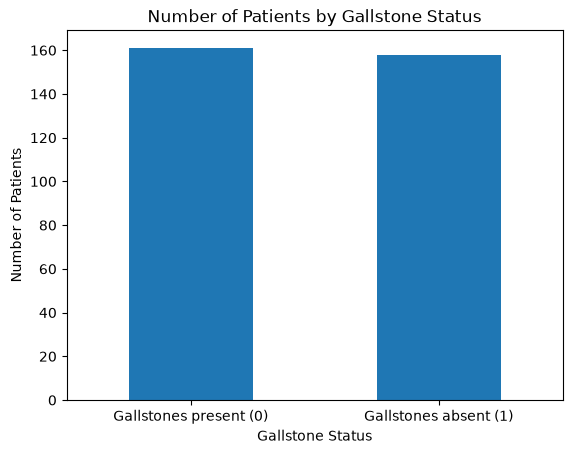

In [11]:
# Plot bar chart to visualise class balance
y.value_counts().sort_index().plot(kind="bar")
plt.xticks([0, 1], ["Gallstones present (0)", "Gallstones absent (1)"], rotation=0)
plt.title("Number of Patients by Gallstone Status")
plt.ylabel("Number of Patients")
plt.show()

In [12]:
# Check baseline accuracy (always predicting the most common class)
baseline = class_counts.max() / len(y)
print("Baseline accuracy:", baseline)

Baseline accuracy: 0.5047021943573667


### Split the data into training/testing sets (5% testing, 95% training)

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.05, random_state = 42)

In [14]:
# Define classifiers for Decision Tree and Random Forest models
classifiers = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}

In [15]:
# Train and evaluate model classifiers
results = []

for name, classifier in classifiers.items():

    # Train the classifier
    classifier.fit(X_train, y_train)

    # Predict on the test set
    y_pred = classifier.predict(X_test)

    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']

    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

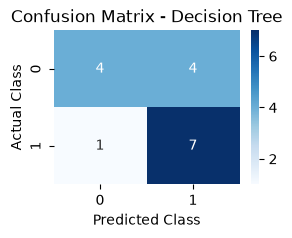

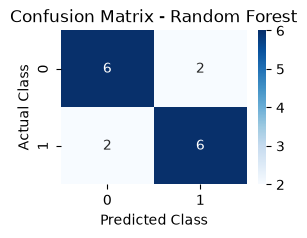

In [16]:
# Create confusion matrix
for name, classifier in classifiers.items():
    y_pred = classifier.predict(X_test)
    conf_matrix = confusion_matrix(y_test, y_pred, labels=[0, 1])

    # Plot confusion matrix
    plt.figure(figsize=(3, 2))

    sns.heatmap(
    conf_matrix,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=["0", "1"],
    yticklabels=["0", "1"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")

    plt.show()

In [17]:
# Convert results to DataFrame
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set:")

print(results_df)

Model Performance Metrics on Test Set:
           Model  Accuracy  Precision  Recall  F1 Score
0  Decision Tree    0.6875   0.718182  0.6875  0.676113
1  Random Forest    0.7500   0.750000  0.7500  0.750000


In [18]:
# Cross validation for accuracy
cv_results = []
for name, classifier in classifiers.items():
    cv_scores = cross_val_score(classifier, X_train, y_train, cv=5, scoring='accuracy')
    cv_results.append([name, cv_scores.mean()])

# Display cross-validation results
cv_results_df = pd.DataFrame(cv_results, columns=["Model", "Mean CV Accuracy"])
print("\nCross-Validation Accuracy Scores:")
print(cv_results_df)


Cross-Validation Accuracy Scores:
           Model  Mean CV Accuracy
0  Decision Tree           0.63377
1  Random Forest           0.78224


### Split the data into training/testing sets (15% testing, 85% training)

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.15, random_state = 42)

In [20]:
# Define classifiers for Decision Tree and Random Forest models
classifiers = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}

In [21]:
# Train and evaluate model classifiers
results = []

for name, classifier in classifiers.items():

    # Train the classifier
    classifier.fit(X_train, y_train)

    # Predict on the test set
    y_pred = classifier.predict(X_test)

    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']

    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

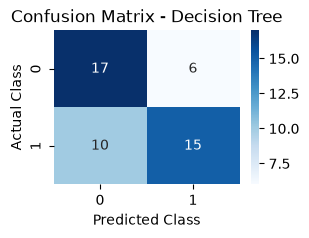

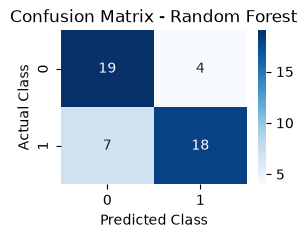

In [22]:
# Create confusion matrix
for name, classifier in classifiers.items():
    y_pred = classifier.predict(X_test)
    conf_matrix = confusion_matrix(y_test, y_pred, labels=[0, 1])

    # Plot confusion matrix
    plt.figure(figsize=(3, 2))

    sns.heatmap(
    conf_matrix,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=["0", "1"],
    yticklabels=["0", "1"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")

    plt.show()

In [23]:
# Convert results to DataFrame
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set:")

print(results_df)

Model Performance Metrics on Test Set:
           Model  Accuracy  Precision    Recall  F1 Score
0  Decision Tree  0.666667   0.673721  0.666667  0.665507
1  Random Forest  0.770833   0.776297  0.770833  0.770535


In [24]:
# Cross validation for accuracy
cv_results = []
for name, classifier in classifiers.items():
    cv_scores = cross_val_score(classifier, X_train, y_train, cv=5, scoring='accuracy')
    cv_results.append([name, cv_scores.mean()])

# Display cross-validation results
cv_results_df = pd.DataFrame(cv_results, columns=["Model", "Mean CV Accuracy"])
print("\nCross-Validation Accuracy Scores:")
print(cv_results_df)


Cross-Validation Accuracy Scores:
           Model  Mean CV Accuracy
0  Decision Tree          0.663973
1  Random Forest          0.771178


### Split the data into training and testing sets (25% testing, 75% training) 

In [25]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 42)

In [26]:
# Define classifiers for Decision Tree and Random Forest models
classifiers = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}

In [27]:
# Train and evaluate model classifiers
results = []

for name, classifier in classifiers.items():

    # Train the classifier
    classifier.fit(X_train, y_train)

    # Predict on the test set
    y_pred = classifier.predict(X_test)

    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']

    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

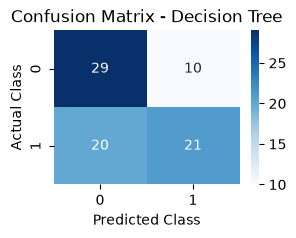

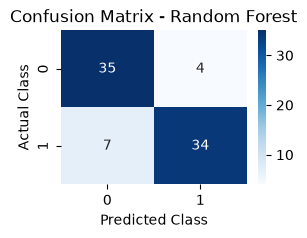

In [28]:
# Create confusion matrix
for name, classifier in classifiers.items():
    y_pred = classifier.predict(X_test)
    conf_matrix = confusion_matrix(y_test, y_pred, labels=[0, 1])

    # Plot confusion matrix
    plt.figure(figsize=(3, 2))

    sns.heatmap(
    conf_matrix,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=["0", "1"],
    yticklabels=["0", "1"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")

    plt.show()

In [29]:
# Convert results to DataFrame
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set:")

print(results_df)

Model Performance Metrics on Test Set:
           Model  Accuracy  Precision  Recall  F1 Score
0  Decision Tree    0.6250   0.635698  0.6250  0.620265
1  Random Forest    0.8625   0.864803  0.8625  0.862436


In [30]:
# Cross validation for accuracy
cv_results = []
for name, classifier in classifiers.items():
    cv_scores = cross_val_score(classifier, X_train, y_train, cv=5, scoring='accuracy')
    cv_results.append([name, cv_scores.mean()])

# Display cross-validation results
cv_results_df = pd.DataFrame(cv_results, columns=["Model", "Mean CV Accuracy"])
print("\nCross-Validation Accuracy Scores:")
print(cv_results_df)


Cross-Validation Accuracy Scores:
           Model  Mean CV Accuracy
0  Decision Tree          0.690337
1  Random Forest          0.765957


### GridSearchCV

GridSearchCV was run on the 25% test split.

In [31]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 42)

In [32]:
classifiers = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}

In [33]:
# Define hyperparameter grids for each classifier
param_grids = {
    "Decision Tree": {
        "max_depth": [3, 5, 7, 10],
        "min_samples_leaf": [1, 2, 4, 8],
    },
    "Random Forest": {
        "n_estimators": [50, 100, 150, 200],
        "max_depth": [None, 5, 10],
        "min_samples_leaf": [1, 2, 4],
    }
}

In [34]:
# Apply GridSearchCV for each classifier and evaluate performance metric scores
results = []
for name, classifier in classifiers.items():
    print(f"Running GridSearchCV for {name}...")
    grid_search = GridSearchCV(estimator=classifier, param_grid=param_grids[name], cv = 5, n_jobs = -1, verbose = 2, scoring='accuracy')
    grid_search.fit(X_train, y_train)
    print(f"Best parameters found: {grid_search.best_params_}")
    print(f"Best cross-validation score: {grid_search.best_score_}")
    print("\n")
    
    # Best model from grid search
    best_model = grid_search.best_estimator_
    
    # Predict on the test set with the best model
    y_pred = best_model.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

Running GridSearchCV for Decision Tree...
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best parameters found: {'max_depth': 3, 'min_samples_leaf': 8}
Best cross-validation score: 0.7071808510638297


Running GridSearchCV for Random Forest...
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best parameters found: {'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 200}
Best cross-validation score: 0.7868794326241134




In [35]:
# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set after GridSearchCV:")
print(results_df)

Model Performance Metrics on Test Set after GridSearchCV:
           Model  Accuracy  Precision  Recall  F1 Score
0  Decision Tree    0.7375   0.767411  0.7375  0.731522
1  Random Forest    0.8250   0.828708  0.8250  0.824781
